# 04 · Experiment 3 — generalization to an unseen manipulation type

**Research question (Exp. 3):** the detectors in Exp. 1–2 were trained and tested on the *same kinds* of fakes. Do they still work when the test
set contains a **manipulation type they never saw in training**?

FakeAVCeleb has three kinds of fake, plus real clips:

| Code | What is fake | In the brief's terms |
|---|---|---|
| RVRA | nothing (real) | genuine |
| RVFA | voice only (cloned) | audio manipulation |
| FVRA | face only (swapped) | visual manipulation |
| FVFA | both | unseen modality *combination* when held out |

**Design.** For each training set made of real clips plus a subset of the fake types, we train on speaker-disjoint training clips and test on
*every* fake type (against real test clips of unseen speakers). A test type that was in the training set is **seen**; otherwise **unseen**.
Seven training sets: each fake type alone (3), each pair (3, the three *leave-one-type-out* cases), and all three (the in-distribution reference).

**Metrics.** For each test type: **ROC-AUC** of real-vs-that-fake-type (threshold-free) and **recall** of that type at a cut-off chosen on a validation
set that contains only *seen* types (the honest setting: you cannot tune on a manipulation you have not met). Real-clip accuracy at the same cut-off is reported too.

**Systems** (same frozen features and same speaker-disjoint 5 splits as Exp. 1–2): voice only, face only, early concatenation, late mean, late max
("fake if either modality says fake"), late stacked, and two small neural networks (concatenation MLP; gated + modality dropout, the best of Exp. 2).
Noisy-OR is left out: it behaved like max in Exp. 2.

**What to expect (hypotheses, not results).** A voice detector trained on fake voices should transfer between RVFA and FVFA (both have a fake voice) but not to FVRA;
a face detector the reverse. The informative case is *leave-FVRA-out* (train on voice-only + both-fake, test on face-only): the face cues must be learned from clips whose
voice is *also* fake, and then recognised when the voice is genuine.

**Scope note.** This is cross-*manipulation* generalization inside FakeAVCeleb. A cross-*dataset* test (e.g. AV-Deepfake1M) would be a stronger second test but needs its EULA and a large download.

**How to run on Kaggle:** add only your `FakeAVCeleb-features` dataset, accelerator None or GPU, Internet off, normal **Run All**. First set `QUICK = True` (1 split, 5 epochs) to check the neural cells,
then `QUICK = False`. Classical results are saved before the neural part starts.

In [9]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

warnings.filterwarnings("ignore")
try:
    display
except NameError:
    display = lambda x: print(x.to_string() if hasattr(x, "to_string") else x)

QUICK = False
SEED = 42
N_SPLITS = 1 if QUICK else 5
EPOCHS = 5 if QUICK else 80
PATIENCE = 15
MOD_DROP = 0.3
CS = [1e-3, 1e-2, 1e-1, 1, 10]
OUT = os.environ.get("EXP_OUT", "/kaggle/working/exp3")
os.makedirs(OUT, exist_ok=True)

FAKE = ["RVFA", "FVRA", "FVFA"]
NICE = {"RVFA": "voice-fake", "FVRA": "face-fake", "FVFA": "both-fake"}
SETTINGS = [("RVFA",), ("FVRA",), ("FVFA",), ("RVFA", "FVRA"), ("RVFA", "FVFA"), ("FVRA", "FVFA"), ("RVFA", "FVRA", "FVFA")]
sname = lambda S: "+".join(S)
slabel = lambda S: "all three" if len(S) == 3 else " + ".join(NICE[c] for c in S)

def find(name):
    cands = []
    if os.environ.get("FEAT_DIR"):
        cands.append(os.path.join(os.environ["FEAT_DIR"], name))
    cands.append(os.path.join("/kaggle/working/features", name))
    cands += glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    for c in cands:
        if os.path.exists(c):
            return c
    raise FileNotFoundError(f"{name} not found. Add the FakeAVCeleb-features dataset as an input.")

FEAT_NPZ, META_CSV = find("features.npz"), find("meta.csv")
print("features:", FEAT_NPZ, "\nmeta:    ", META_CSV, "\nQUICK =", QUICK)

features: /kaggle/input/datasets/aryavartsinghpayal/fakeavceleb-features/features.npz 
meta:     /kaggle/input/datasets/aryavartsinghpayal/fakeavceleb-features/meta.csv 
QUICK = False


## 1 · Load features (identical to Exp. 1–2)

In [10]:
Z = np.load(FEAT_NPZ)
meta = pd.read_csv(META_CSV).sort_values("clip_id").reset_index(drop=True)
assert (Z["clip_id"] == meta.clip_id.values).all(), "features.npz and meta.csv are out of sync"
keep = ((meta.ok_img == 1) & (meta.ok_aud == 1)).values
meta = meta[keep].reset_index(drop=True)
A_LAYERS, IMG = Z["audio_layers"][keep], Z["image"][keep]
y = meta.label.values
groups = meta.speaker.values
cats = meta.category.values
print("clips:", len(meta), "| per category:", pd.Series(cats).value_counts().to_dict())

def grouped_split(seed, val=0.15, test=0.15):
    idx = np.arange(len(y))
    trv, te = next(GroupShuffleSplit(1, test_size=test, random_state=seed).split(idx, groups=groups))
    a, b = next(GroupShuffleSplit(1, test_size=val / (1 - test), random_state=seed).split(trv, groups=groups[trv]))
    return trv[a], trv[b], te

SPLITS = [grouped_split(SEED + s) for s in range(N_SPLITS)]

def restrict(idx, S):
    """keep real clips and only the fake types in S"""
    return idx[np.isin(cats[idx], ("RVRA",) + tuple(S))]

for s, (tr, va, te) in enumerate(SPLITS[:1]):
    print("split 0 train clips per setting:")
    for S in SETTINGS:
        r = restrict(tr, S)
        print(f"  {slabel(S):32s} n={len(r):4d}  real={int((cats[r] == 'RVRA').sum()):4d}  fake={int((cats[r] != 'RVRA').sum()):4d}")
    print("split 0 test clips per category:", pd.Series(cats[te]).value_counts().to_dict())

clips: 998 | per category: {'RVRA': 500, 'FVRA': 166, 'RVFA': 166, 'FVFA': 166}
split 0 train clips per setting:
  voice-fake                       n= 473  real= 350  fake= 123
  face-fake                        n= 462  real= 350  fake= 112
  both-fake                        n= 458  real= 350  fake= 108
  voice-fake + face-fake           n= 585  real= 350  fake= 235
  voice-fake + both-fake           n= 581  real= 350  fake= 231
  face-fake + both-fake            n= 570  real= 350  fake= 220
  all three                        n= 693  real= 350  fake= 343
split 0 test clips per category: {'RVRA': 75, 'FVFA': 30, 'FVRA': 26, 'RVFA': 23}


## 2 · Helpers

In [11]:
def scale(tr, *others):
    sc = StandardScaler().fit(tr)
    return (sc.transform(tr),) + tuple(sc.transform(o) for o in others)

def fit_lr(Xtr, ytr, Xva, yva):
    best = None
    for C in CS:
        clf = LogisticRegression(C=C, class_weight="balanced", max_iter=3000).fit(Xtr, ytr)
        auc = roc_auc_score(yva, clf.predict_proba(Xva)[:, 1])
        if best is None or auc > best[0]:
            best = (auc, C, clf)
    return best[2], best[1]

def val_threshold(yv, pv):
    """cut-off maximising balanced accuracy on validation (which holds only SEEN types); ties -> closest to 0.5"""
    grid = np.linspace(0.05, 0.95, 91)
    sc = np.array([balanced_accuracy_score(yv, (pv >= t).astype(int)) for t in grid])
    cand = grid[sc >= sc.max() - 1e-12]
    return float(cand[np.argmin(np.abs(cand - 0.5))])

logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))

def eval_rows(system, split_id, S, pv, pt, vaS, te):
    thr = val_threshold(y[vaS], pv)
    real = cats[te] == "RVRA"
    tnr = float((pt[real] < thr).mean())
    rows = []
    for c in FAKE:
        mk = cats[te] == c
        if not mk.any():
            continue
        yy = np.r_[np.zeros(int(real.sum())), np.ones(int(mk.sum()))]
        pp = np.r_[pt[real], pt[mk]]
        rows.append(dict(split=split_id, train=sname(S), system=system, test=c, seen=bool(c in S),
                         auc=roc_auc_score(yy, pp), recall=float((pt[mk] >= thr).mean()), tnr=tnr, thr=thr))
    return rows

## 3 · Classical systems

In [12]:
def classical(trS, vaS, te):
    M = A_LAYERS.mean(1)
    A = scale(M[trS], M[vaS], M[te])
    I = scale(IMG[trS], IMG[vaS], IMG[te])
    P = {}
    for k, X in (("A", A), ("I", I)):
        clf, C = fit_lr(X[0], y[trS], X[1], y[vaS])
        P[k] = dict(C=C, X=X, va=clf.predict_proba(X[1])[:, 1], te=clf.predict_proba(X[2])[:, 1])
    Xc = [np.hstack([A[j], I[j]]) for j in range(3)]
    clf, _ = fit_lr(Xc[0], y[trS], Xc[1], y[vaS])
    out = {"Voice only": (P["A"]["va"], P["A"]["te"]),
           "Face only": (P["I"]["va"], P["I"]["te"]),
           "Early concat (LR)": (clf.predict_proba(Xc[1])[:, 1], clf.predict_proba(Xc[2])[:, 1]),
           "Late: mean": ((P["A"]["va"] + P["I"]["va"]) / 2, (P["A"]["te"] + P["I"]["te"]) / 2),
           "Late: max (either says fake)": (np.maximum(P["A"]["va"], P["I"]["va"]), np.maximum(P["A"]["te"], P["I"]["te"]))}
    oof = {k: np.zeros(len(trS)) for k in P}
    for itr, iva in GroupKFold(n_splits=5).split(trS, groups=groups[trS]):
        for k in P:
            m = LogisticRegression(C=P[k]["C"], class_weight="balanced", max_iter=3000).fit(P[k]["X"][0][itr], y[trS][itr])
            oof[k][iva] = m.predict_proba(P[k]["X"][0][iva])[:, 1]
    meta_clf = LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000).fit(np.c_[logit(oof["A"]), logit(oof["I"])], y[trS])
    stack = lambda s: meta_clf.predict_proba(np.c_[logit(P["A"][s]), logit(P["I"][s])])[:, 1]
    out["Late: stacked LR"] = (stack("va"), stack("te"))
    return out

rows, t0 = [], time.time()
for s, (tr, va, te) in enumerate(SPLITS):
    for S in SETTINGS:
        trS, vaS = restrict(tr, S), restrict(va, S)
        for name, (pv, pt) in classical(trS, vaS, te).items():
            rows += eval_rows(name, s, S, pv, pt, vaS, te)
    print(f"split {s} classical done ({time.time() - t0:.0f}s)")
df_cls = pd.DataFrame(rows)
df_cls.to_csv(f"{OUT}/exp3_classical_long.csv", index=False)
print("saved classical results:", len(df_cls), "rows")

split 0 classical done (26s)
split 1 classical done (53s)
split 2 classical done (76s)
split 3 classical done (106s)
split 4 classical done (134s)
saved classical results: 630 rows


## 4 · Neural systems (PyTorch) — concatenation MLP and gated + modality dropout

In [13]:
try:
    import torch, torch.nn as nn
    HAVE_TORCH = True
except Exception as e:
    HAVE_TORCH = False
    print("PyTorch not available -> neural systems skipped:", e)

df_nn = pd.DataFrame()
if HAVE_TORCH:
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    print("device:", dev)

    def proj(d_in, d, p):
        return nn.Sequential(nn.Dropout(p), nn.Linear(d_in, d), nn.LayerNorm(d), nn.GELU())

    class ConcatMLP(nn.Module):
        def __init__(s, d=128, p=0.3):
            super().__init__()
            s.pa, s.pi = proj(768, d, p), proj(512, d, p)
            s.head = nn.Sequential(nn.Dropout(p), nn.Linear(2 * d, d), nn.GELU(), nn.Linear(d, 1))
        def forward(s, a, i):
            return s.head(torch.cat([s.pa(a.mean(1)), s.pi(i)], -1)).squeeze(-1)

    class Gated(nn.Module):
        def __init__(s, d=128, p=0.3):
            super().__init__()
            s.pa, s.pi = proj(768, d, p), proj(512, d, p)
            s.gate = nn.Linear(2 * d, d)
            s.head = nn.Sequential(nn.Dropout(p), nn.Linear(d, 1))
        def forward(s, a, i):
            ha, hi = s.pa(a.mean(1)), s.pi(i)
            g = torch.sigmoid(s.gate(torch.cat([ha, hi], -1)))
            return s.head(g * ha + (1 - g) * hi).squeeze(-1)

    NN_SYSTEMS = [("Concat-MLP", ConcatMLP, 0.0), ("Gated + modality dropout", Gated, MOD_DROP)]

    def prep_tensors(trS):
        mu, sd = A_LAYERS[trS].mean(0, keepdims=True), A_LAYERS[trS].std(0, keepdims=True) + 1e-6
        mi, si = IMG[trS].mean(0, keepdims=True), IMG[trS].std(0, keepdims=True) + 1e-6
        return (torch.tensor((A_LAYERS - mu) / sd, dtype=torch.float32, device=dev),
                torch.tensor((IMG - mi) / si, dtype=torch.float32, device=dev))

    def train_neural(cls, Xa, Xi, trS, vaS, te, mod_drop, seed):
        torch.manual_seed(seed); np.random.seed(seed)
        model = cls().to(dev)
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
        pw = float((y[trS] == 0).sum()) / max(float((y[trS] == 1).sum()), 1.0)      # classes are unbalanced when only one fake type is used
        lossf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pw], dtype=torch.float32, device=dev))
        yt = torch.tensor(y, dtype=torch.float32, device=dev)
        tr_t, va_t, te_t = (torch.as_tensor(ix, device=dev) for ix in (trS, vaS, te))
        best_auc, best_state, bad = -1.0, None, 0
        for ep in range(EPOCHS):
            model.train()
            perm = tr_t[torch.randperm(len(tr_t), device=dev)]
            for k in range(0, len(perm), 64):
                idx = perm[k:k + 64]
                a, i, t = Xa[idx], Xi[idx], yt[idx]
                if mod_drop > 0:
                    r = torch.rand(len(idx), device=dev)
                    a = a * (r >= mod_drop / 2).float()[:, None, None]
                    i = i * ((r < mod_drop / 2) | (r >= mod_drop)).float()[:, None]
                loss = lossf(model(a, i), t)
                opt.zero_grad(); loss.backward(); opt.step()
            model.eval()
            with torch.no_grad():
                pv = torch.sigmoid(model(Xa[va_t], Xi[va_t])).cpu().numpy()
            auc = roc_auc_score(y[vaS], pv)
            if auc > best_auc:
                best_auc, bad = auc, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
                if bad >= PATIENCE:
                    break
        model.load_state_dict(best_state); model.eval()
        with torch.no_grad():
            pv = torch.sigmoid(model(Xa[va_t], Xi[va_t])).cpu().numpy()
            pt = torch.sigmoid(model(Xa[te_t], Xi[te_t])).cpu().numpy()
        return pv, pt

    rows, t0 = [], time.time()
    for s, (tr, va, te) in enumerate(SPLITS):
        for S in SETTINGS:
            trS, vaS = restrict(tr, S), restrict(va, S)
            Xa, Xi = prep_tensors(trS)
            for name, cls, md in NN_SYSTEMS:
                pv, pt = train_neural(cls, Xa, Xi, trS, vaS, te, md, SEED + s)
                rows += eval_rows(name, s, S, pv, pt, vaS, te)
        print(f"split {s} neural done ({time.time() - t0:.0f}s)")
    df_nn = pd.DataFrame(rows)
    df_nn.to_csv(f"{OUT}/exp3_neural_long.csv", index=False)

df = pd.concat([df_cls, df_nn], ignore_index=True)
df.to_csv(f"{OUT}/exp3_all_long.csv", index=False)
order = [n for n in ["Voice only", "Face only", "Early concat (LR)", "Late: mean", "Late: max (either says fake)", "Late: stacked LR",
                     "Concat-MLP", "Gated + modality dropout"] if n in set(df.system)]
print("systems:", order)

device: cpu
split 0 neural done (27s)
split 1 neural done (55s)
split 2 neural done (78s)
split 3 neural done (102s)
split 4 neural done (126s)
systems: ['Voice only', 'Face only', 'Early concat (LR)', 'Late: mean', 'Late: max (either says fake)', 'Late: stacked LR', 'Concat-MLP', 'Gated + modality dropout']


## 5 · Result A — leave-one-type-out (the core test)
Train on real + two fake types, test on the third (never seen). AUC = real-vs-that-type, mean ± std over splits. The last block is the same test type when it **was** in training (all three), for reference.

In [14]:
LOO = [(("RVFA", "FVFA"), "FVRA", "face-fake unseen"), (("FVRA", "FVFA"), "RVFA", "voice-fake unseen"), (("RVFA", "FVRA"), "FVFA", "both-fake unseen")]
ms = lambda v: f"{v.mean():.3f} ± {v.std():.3f}" if len(v) > 1 else f"{v.mean():.3f}"

tabA = pd.DataFrame(index=order)
for S, c, lab in LOO:
    sub = df[(df.train == sname(S)) & (df.test == c)]
    tabA[f"AUC · {lab}"] = [ms(sub[sub.system == n].auc.values) for n in order]
for S, c, lab in LOO:
    sub = df[(df.train == "RVFA+FVRA+FVFA") & (df.test == c)]
    tabA[f"AUC · {c} seen (reference)"] = [ms(sub[sub.system == n].auc.values) for n in order]
display(tabA)
tabA.to_csv(f"{OUT}/exp3_A_leave_one_type_out_auc.csv")

tabA2 = pd.DataFrame(index=order)
for S, c, lab in LOO:
    sub = df[(df.train == sname(S)) & (df.test == c)]
    tabA2[f"recall · {lab}"] = [ms(sub[sub.system == n].recall.values) for n in order]
    tabA2[f"real accepted · {lab}"] = [ms(sub[sub.system == n].tnr.values) for n in order]
print("\nRecall of the unseen type, and accuracy on real clips, at the cut-off tuned on SEEN types only:")
display(tabA2)
tabA2.to_csv(f"{OUT}/exp3_A_leave_one_type_out_recall.csv")

,AUC · face-fake unseen,AUC · voice-fake unseen,AUC · both-fake unseen,AUC · FVRA seen (reference),AUC · RVFA seen (reference),AUC · FVFA seen (reference)
Voice only,0.555 ± 0.035,0.976 ± 0.047,0.951 ± 0.050,0.531 ± 0.033,0.996 ± 0.008,0.993 ± 0.014
Face only,0.796 ± 0.050,0.453 ± 0.050,0.820 ± 0.046,0.894 ± 0.028,0.572 ± 0.046,0.892 ± 0.026
Early concat (LR),0.603 ± 0.031,0.892 ± 0.054,0.994 ± 0.006,0.810 ± 0.028,0.993 ± 0.009,0.997 ± 0.005
Late: mean,0.792 ± 0.053,0.888 ± 0.041,0.951 ± 0.039,0.860 ± 0.041,0.975 ± 0.021,0.990 ± 0.009
Late: max (either says fake),0.792 ± 0.056,0.932 ± 0.048,0.944 ± 0.036,0.874 ± 0.040,0.986 ± 0.010,0.982 ± 0.013
Late: stacked LR,0.611 ± 0.041,0.785 ± 0.064,0.965 ± 0.034,0.846 ± 0.048,0.995 ± 0.005,0.997 ± 0.004
Concat-MLP,0.605 ± 0.029,0.929 ± 0.040,0.996 ± 0.004,0.824 ± 0.023,0.998 ± 0.002,0.999 ± 0.001
Gated + modality dropout,0.639 ± 0.043,0.981 ± 0.015,0.998 ± 0.003,0.837 ± 0.031,0.999 ± 0.001,1.000 ± 0.000



Recall of the unseen type, and accuracy on real clips, at the cut-off tuned on SEEN types only:


,recall · face-fake unseen,real accepted · face-fake unseen,recall · voice-fake unseen,real accepted · voice-fake unseen,recall · both-fake unseen,real accepted · both-fake unseen
Voice only,0.000 ± 0.000,0.997 ± 0.005,0.952 ± 0.095,0.912 ± 0.075,0.909 ± 0.126,0.893 ± 0.075
Face only,0.759 ± 0.090,0.683 ± 0.049,0.117 ± 0.063,0.837 ± 0.066,0.796 ± 0.070,0.656 ± 0.171
Early concat (LR),0.000 ± 0.000,0.997 ± 0.005,0.762 ± 0.184,0.840 ± 0.022,0.993 ± 0.013,0.835 ± 0.047
Late: mean,0.181 ± 0.222,0.936 ± 0.095,0.751 ± 0.217,0.864 ± 0.063,0.926 ± 0.066,0.861 ± 0.044
Late: max (either says fake),0.410 ± 0.149,0.912 ± 0.073,0.930 ± 0.089,0.893 ± 0.030,0.948 ± 0.066,0.811 ± 0.041
Late: stacked LR,0.000 ± 0.000,0.997 ± 0.005,0.444 ± 0.105,0.869 ± 0.073,0.944 ± 0.050,0.859 ± 0.065
Concat-MLP,0.000 ± 0.000,0.992 ± 0.007,0.842 ± 0.119,0.848 ± 0.085,0.993 ± 0.013,0.861 ± 0.076
Gated + modality dropout,0.010 ± 0.019,0.995 ± 0.007,0.935 ± 0.093,0.885 ± 0.076,1.000 ± 0.000,0.899 ± 0.058


## 6 · Result B — full transfer matrix (train set × test type)
Mean AUC per system. Outlined cells = the test type **was** in training (seen). Below 0.5 means *worse than guessing* on that type.

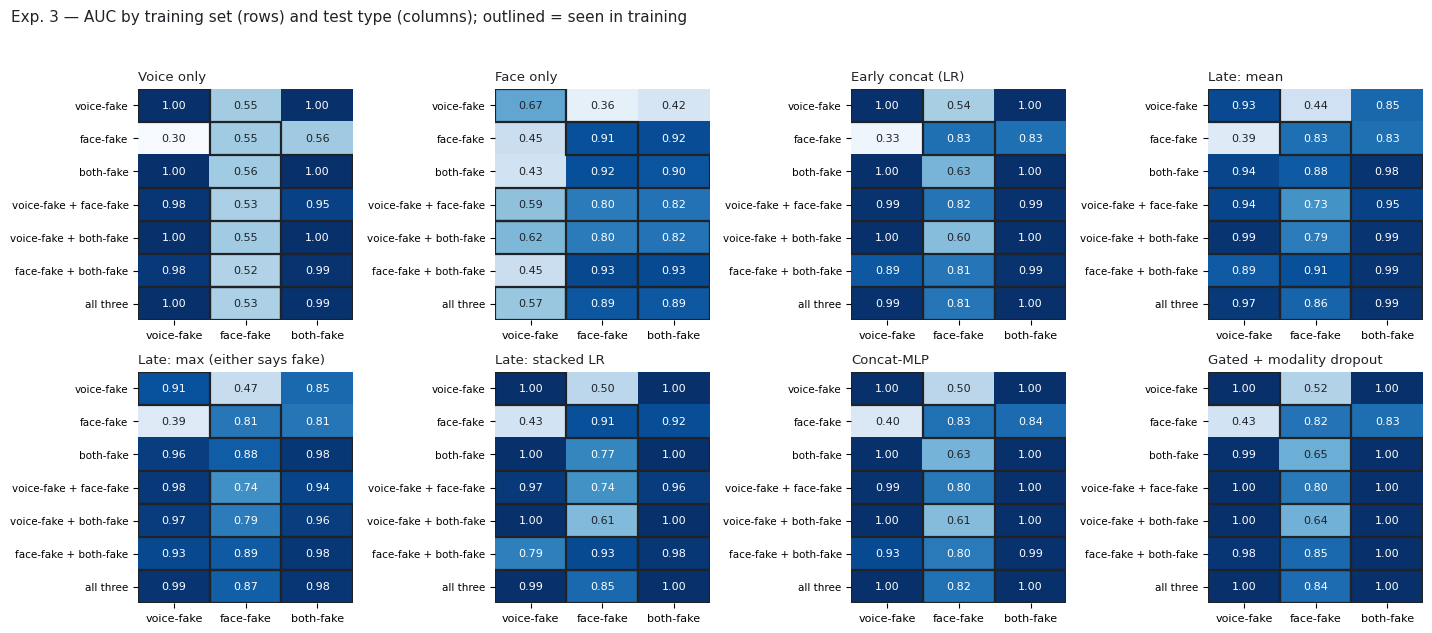

In [15]:
def matrix(system, col="auc"):
    M = np.full((len(SETTINGS), len(FAKE)), np.nan)
    for i, S in enumerate(SETTINGS):
        for j, c in enumerate(FAKE):
            v = df[(df.system == system) & (df.train == sname(S)) & (df.test == c)][col].values
            if len(v):
                M[i, j] = v.mean()
    return M

INK, MUTED, GRID, BLUE = "#1f2328", "#6b7280", "#e5e7eb", "#2f6db5"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": GRID})
ncol = 4 if len(order) > 6 else 3
nrow = int(np.ceil(len(order) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.2 * nrow), squeeze=False)
for ax, n in zip(axes.ravel(), order):
    M = matrix(n)
    ax.imshow(M, cmap="Blues", vmin=0.3, vmax=1.0, aspect="auto")
    for i, S in enumerate(SETTINGS):
        for j, c in enumerate(FAKE):
            if np.isnan(M[i, j]):
                continue
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if M[i, j] > 0.7 else INK)
            if c in S:
                ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=INK, lw=1.6))
    ax.set_xticks(range(3)); ax.set_xticklabels([NICE[c] for c in FAKE], fontsize=8)
    ax.set_yticks(range(len(SETTINGS))); ax.set_yticklabels([slabel(S) for S in SETTINGS], fontsize=7.5)
    ax.set_title(n, fontsize=9.5, color=INK, loc="left")
    for sp in ax.spines.values():
        sp.set_visible(False)
for ax in axes.ravel()[len(order):]:
    ax.axis("off")
fig.suptitle("Exp. 3 — AUC by training set (rows) and test type (columns); outlined = seen in training", x=0.01, ha="left", fontsize=11, color=INK)
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.savefig(f"{OUT}/exp3_transfer_matrix.png", dpi=170); plt.show()

## 7 · Result C — seen vs unseen, per system
Mean AUC over cells where the test type was in training (seen) against cells where it was not (unseen), and the paired change against early concatenation.

,AUC seen,AUC unseen,drop (seen − unseen),recall of unseen types,real accepted
system,,,,,
Voice only,0.842,0.716,0.126,0.470,0.931
Face only,0.794,0.620,0.174,0.411,0.764
Early concat (LR),0.936,0.757,0.179,0.488,0.919
Late: mean,0.926,0.773,0.153,0.501,0.857
Late: max (either says fake),0.921,0.780,0.141,0.630,0.850
Late: stacked LR,0.947,0.775,0.172,0.475,0.915
Concat-MLP,0.936,0.766,0.170,0.503,0.916
Gated + modality dropout,0.941,0.782,0.159,0.530,0.924



Paired change in unseen-type AUC (same splits):


,Δ unseen AUC vs early concat,wins
system,,
Voice only,-0.041,1/5
Face only,-0.138,0/5
Late: mean,0.016,4/5
Late: max (either says fake),0.023,4/5
Late: stacked LR,0.017,4/5
Concat-MLP,0.009,3/5
Gated + modality dropout,0.025,5/5


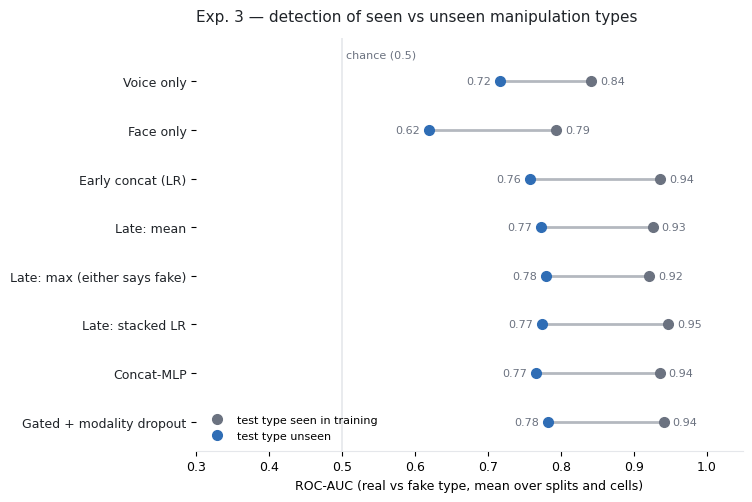

In [16]:
per_split = df.groupby(["system", "split", "seen"]).auc.mean().unstack("seen")
per_split.columns = ["unseen" if not c else "seen" for c in per_split.columns]
summ = per_split.groupby("system").agg(["mean", "std"]).loc[order]
tabC = pd.DataFrame({"AUC seen": summ[("seen", "mean")], "AUC unseen": summ[("unseen", "mean")]})
tabC["drop (seen − unseen)"] = tabC["AUC seen"] - tabC["AUC unseen"]
rec = df[~df.seen].groupby("system").recall.mean().loc[order]
tabC["recall of unseen types"] = rec
tabC["real accepted"] = df.groupby("system").tnr.mean().loc[order]
display(tabC.round(3))
tabC.round(4).to_csv(f"{OUT}/exp3_C_seen_vs_unseen.csv")

base = per_split.xs("Early concat (LR)", level="system")["unseen"]
paired = []
for n in order:
    if n == "Early concat (LR)":
        continue
    d = per_split.xs(n, level="system")["unseen"] - base
    paired.append({"system": n, "Δ unseen AUC vs early concat": d.mean(), "wins": f"{int((d > 0).sum())}/{len(d)}"})
paired = pd.DataFrame(paired).set_index("system").round(3)
print("\nPaired change in unseen-type AUC (same splits):")
display(paired)
paired.to_csv(f"{OUT}/exp3_C_paired_unseen_auc.csv")

fig, ax = plt.subplots(figsize=(7.6, 0.45 * len(order) + 1.5))
yy = np.arange(len(order))[::-1]
se, un = tabC["AUC seen"].values, tabC["AUC unseen"].values
ax.hlines(yy, np.minimum(se, un), np.maximum(se, un), color=MUTED, lw=2, alpha=0.5)
ax.plot(se, yy, "o", color=MUTED, ms=7, label="test type seen in training")
ax.plot(un, yy, "o", color=BLUE, ms=7, label="test type unseen")
for a, b, yv in zip(se, un, yy):
    ax.text(min(a, b) - 0.012, yv, f"{min(a, b):.2f}", ha="right", va="center", fontsize=8, color=MUTED)
    ax.text(max(a, b) + 0.012, yv, f"{max(a, b):.2f}", ha="left", va="center", fontsize=8, color=MUTED)
ax.axvline(0.5, color=GRID, lw=1.2)
ax.set_ylim(-0.6, len(order) - 0.1)
ax.text(0.505, len(order) - 0.45, "chance (0.5)", ha="left", va="center", fontsize=8, color=MUTED)
ax.set_yticks(yy); ax.set_yticklabels(order, color=INK)
ax.set_xlabel("ROC-AUC (real vs fake type, mean over splits and cells)")
ax.set_xlim(0.3, 1.05); ax.legend(loc="lower left", fontsize=8, frameon=False)
for sp in ("top", "right", "left"):
    ax.spines[sp].set_visible(False)
ax.set_title("Exp. 3 — detection of seen vs unseen manipulation types", loc="left", color=INK, fontsize=11, pad=12)
plt.tight_layout(); plt.savefig(f"{OUT}/exp3_seen_vs_unseen.png", dpi=170); plt.show()